In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [38]:
df = pd.read_csv("../data/Complications_and_Deaths-Hospital.csv")

print("Dataset loaded successfully!")
print("Rows and Columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and Columns: (95800, 18)


,Facility ID,Facility Name,Address,City/Town,State,ZIP Code,County/Parish,Telephone Number,Measure ID,Measure Name,Compared to National,Denominator,Score,Lower Estimate,Higher Estimate,Footnote,Start Date,End Date
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,COMP_HIP_KNEE,Rate of complications for hip/knee replacement...,Not Available,33,3.8,Not Available,Not Available,NaN,04/01/2023,03/31/2025
1,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,Hybrid_HWM,Hybrid Hospital-Wide All-Cause Risk Standardiz...,Not Available,4972,4.4,Not Available,Not Available,NaN,07/01/2024,06/30/2025
2,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,MORT_30_AMI,Death rate for heart attack patients,Not Available,234,13.5,Not Available,Not Available,NaN,07/01/2022,06/30/2025
3,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,MORT_30_CABG,Death rate for CABG surgery patients,Not Available,127,3.2,Not Available,Not Available,NaN,07/01/2022,06/30/2025
4,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,MORT_30_COPD,Death rate for COPD patients,Not Available,116,9.1,Not Available,Not Available,NaN,07/01/2022,06/30/2025


In [39]:
df.shape

(95800, 18)

In [40]:
df.columns.tolist()

['Facility ID',
 'Facility Name',
 'Address',
 'City/Town',
 'State',
 'ZIP Code',
 'County/Parish',
 'Telephone Number',
 'Measure ID',
 'Measure Name',
 'Compared to National',
 'Denominator',
 'Score',
 'Lower Estimate',
 'Higher Estimate',
 'Footnote',
 'Start Date',
 'End Date']

In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 95800 entries, 0 to 95799
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Facility ID           95800 non-null  str  
 1   Facility Name         95800 non-null  str  
 2   Address               95800 non-null  str  
 3   City/Town             95800 non-null  str  
 4   State                 95800 non-null  str  
 5   ZIP Code              95800 non-null  int64
 6   County/Parish         95800 non-null  str  
 7   Telephone Number      95800 non-null  str  
 8   Measure ID            95800 non-null  str  
 9   Measure Name          95800 non-null  str  
 10  Compared to National  95800 non-null  str  
 11  Denominator           95800 non-null  str  
 12  Score                 95800 non-null  str  
 13  Lower Estimate        95800 non-null  str  
 14  Higher Estimate       95800 non-null  str  
 15  Footnote              44583 non-null  str  
 16  Start Date     

In [42]:
df.isnull().sum()

Facility ID                 0
Facility Name               0
Address                     0
City/Town                   0
State                       0
ZIP Code                    0
County/Parish               0
Telephone Number            0
Measure ID                  0
Measure Name                0
Compared to National        0
Denominator                 0
Score                       0
Lower Estimate              0
Higher Estimate             0
Footnote                51217
Start Date                  0
End Date                    0
dtype: int64

In [43]:
df["Score"].value_counts().head(15)

Score
Not Available    43408
0.27               772
0.21               728
0.20               653
0.26               650
0.25               462
3.9                372
3.7                371
3.8                369
4                  366
0.19               363
0.24               333
4.1                326
3.6                324
4.2                319
Name: count, dtype: int64

In [44]:
df["Score_Numeric"] = pd.to_numeric(df["Score"], errors="coerce")

print("Numeric scores:", df["Score_Numeric"].notna().sum())
print("Unavailable scores:", df["Score_Numeric"].isna().sum())

Numeric scores: 52392
Unavailable scores: 43408


In [45]:
df["Measure Name"].value_counts()

Measure Name
Rate of complications for hip/knee replacement patients                      4790
Hybrid Hospital-Wide All-Cause Risk Standardized Mortality Rate              4790
Death rate for heart attack patients                                         4790
Death rate for CABG surgery patients                                         4790
Death rate for COPD patients                                                 4790
Death rate for heart failure patients                                        4790
Death rate for pneumonia patients                                            4790
Death rate for stroke patients                                               4790
Pressure ulcer rate                                                          4790
Death rate among surgical inpatients with serious treatable complications    4790
Iatrogenic pneumothorax rate                                                 4790
In-hospital fall-associated fracture rate                                    4790
Pos

In [46]:
# Analyze score availability across hospital quality measures

# Count total records and available numeric scores for each measure
measure_summary = df.groupby("Measure Name").agg(
    Total_Records=("Score", "size"),
    Available_Scores=("Score_Numeric", "count")
)

# Calculate the number of unavailable scores
measure_summary["Unavailable_Scores"] = (
    measure_summary["Total_Records"] - measure_summary["Available_Scores"]
)

# Calculate the percentage of available scores
measure_summary["Availability_Percent"] = (
    measure_summary["Available_Scores"]
    / measure_summary["Total_Records"] * 100
).round(2)

# Display measures ranked by data availability
measure_summary.sort_values("Availability_Percent", ascending=False)

,Total_Records,Available_Scores,Unavailable_Scores,Availability_Percent
Measure Name,,,,
Hybrid Hospital-Wide All-Cause Risk Standardized Mortality Rate,4790,4261,529,88.96
Death rate for pneumonia patients,4790,3639,1151,75.97
Iatrogenic pneumothorax rate,4790,3085,1705,64.41
In-hospital fall-associated fracture rate,4790,3084,1706,64.38
Pressure ulcer rate,4790,3056,1734,63.80
Death rate for heart failure patients,4790,3049,1741,63.65
CMS Medicare PSI 90: Patient safety and adverse events composite,4790,2908,1882,60.71
Perioperative pulmonary embolism or deep vein thrombosis rate,4790,2833,1957,59.14
Postoperative hemorrhage or hematoma rate,4790,2826,1964,59.00


In [47]:
# Select hospital-wide mortality records for focused analysis
mortality_df = df[
    df["Measure Name"] ==
    "Hybrid Hospital-Wide All-Cause Risk Standardized Mortality Rate"
].copy()

# Keep records with valid numeric mortality scores
mortality_valid = mortality_df.dropna(subset=["Score_Numeric"]).copy()

# Display the number of available records
print("Total hospital records:", len(mortality_df))
print("Records with valid scores:", len(mortality_valid))

# Generate descriptive statistics for mortality scores
mortality_valid["Score_Numeric"].describe()

Total hospital records: 4790
Records with valid scores: 4261


count    4261.000000
mean        4.036118
std         0.843702
min         1.600000
25%         3.500000
50%         3.900000
75%         4.400000
max        12.800000
Name: Score_Numeric, dtype: float64

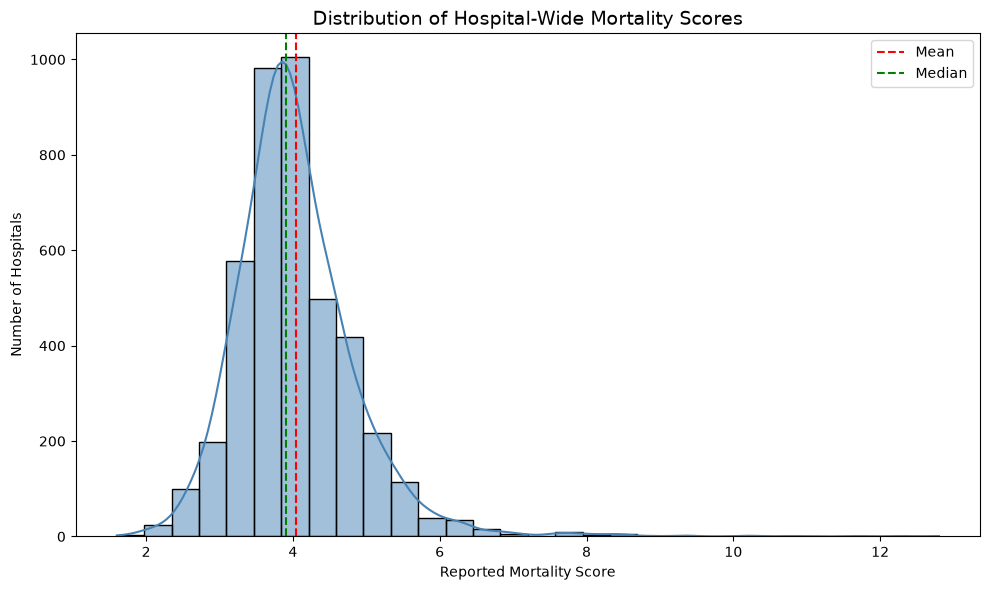

In [48]:
# Create a histogram to examine the distribution of hospital-wide mortality scores
plt.figure(figsize=(10, 6))

# Plot the frequency distribution and a smoothed density curve
sns.histplot(
    data=mortality_valid,
    x="Score_Numeric",
    bins=30,
    kde=True,
    color="steelblue"
)

# Add reference lines for the mean and median
plt.axvline(
    mortality_valid["Score_Numeric"].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

plt.axvline(
    mortality_valid["Score_Numeric"].median(),
    color="green",
    linestyle="--",
    label="Median"
)

# Add a descriptive title and axis labels
plt.title("Distribution of Hospital-Wide Mortality Scores", fontsize=14)
plt.xlabel("Reported Mortality Score")
plt.ylabel("Number of Hospitals")
plt.legend()

# Improve chart spacing and display the visualization
plt.tight_layout()
plt.show()

In [49]:
# Calculate the first and third quartiles of mortality scores
Q1 = mortality_valid["Score_Numeric"].quantile(0.25)
Q3 = mortality_valid["Score_Numeric"].quantile(0.75)

# Calculate the interquartile range (IQR)
IQR = Q3 - Q1

# Define potential outlier boundaries using the 1.5 × IQR rule
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify records with scores outside the calculated boundaries
outliers = mortality_valid[
    (mortality_valid["Score_Numeric"] < lower_bound) |
    (mortality_valid["Score_Numeric"] > upper_bound)
]

# Display the boundaries and number of potential outliers
print("Lower boundary:", round(lower_bound, 2))
print("Upper boundary:", round(upper_bound, 2))
print("Number of potential outliers:", len(outliers))
print("Percentage of potential outliers:",
      round(len(outliers) / len(mortality_valid) * 100, 2), "%")

Lower boundary: 2.15
Upper boundary: 5.75
Number of potential outliers: 138
Percentage of potential outliers: 3.24 %


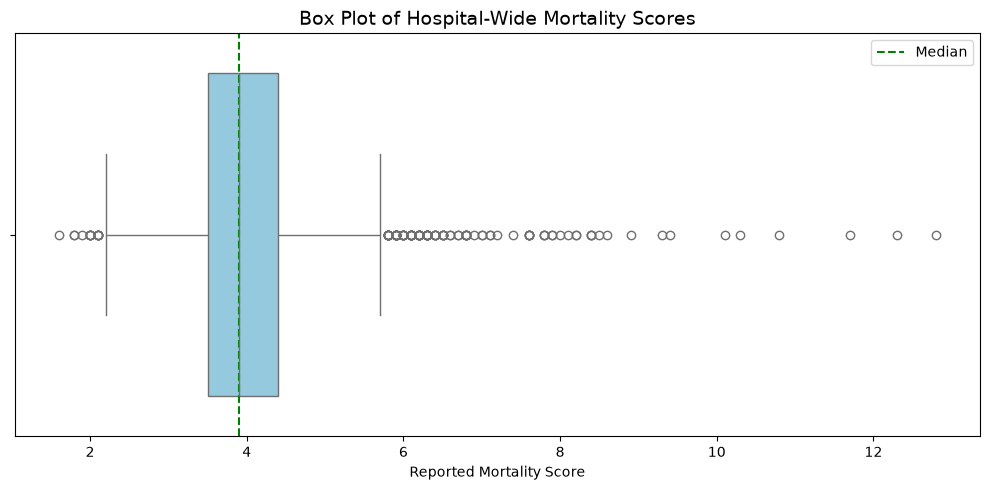

In [50]:
# Create a box plot to visualize hospital-wide mortality scores
plt.figure(figsize=(10, 5))

# Display the distribution and potential outliers
sns.boxplot(
    x=mortality_valid["Score_Numeric"],
    color="skyblue"
)

# Add the chart title and axis labels
plt.title("Box Plot of Hospital-Wide Mortality Scores", fontsize=14)
plt.xlabel("Reported Mortality Score")

# Add a reference line for the median
plt.axvline(
    mortality_valid["Score_Numeric"].median(),
    color="green",
    linestyle="--",
    label="Median"
)

# Display the legend and improve spacing
plt.legend()
plt.tight_layout()
plt.show()

In [51]:
# Identify the 10 hospital records with the highest reported mortality scores
top_mortality_scores = mortality_valid.nlargest(
    10,
    "Score_Numeric"
)

# Display hospital names, locations, and reported scores
top_mortality_scores[
    [
        "Facility Name",
        "State",
        "Score_Numeric",
        "Compared to National"
    ]
]

,Facility Name,State,Score_Numeric,Compared to National
73341,HOSPITAL COMUNITARIO BUEN SAMARITANO INC,PR,12.8,Not Available
73681,HOSPITAL PAVIA CAGUAS,PR,12.3,Not Available
73441,HOSPITAL MENONITA CAGUAS INC,PR,11.7,Not Available
73521,HOSPITAL PAVIA YAUCO,PR,10.8,Not Available
73641,HOSPITAL METROPOLITANO DR SUSONI,PR,10.3,Not Available
73301,HOSPITAL MENONITA GUAYAMA,PR,10.1,Not Available
73421,MAYAGUEZ MEDICAL CENTER DR RAMON EMETERIO BETA...,PR,9.4,Not Available
73601,MANATI MEDICAL CENTER DR OTERO LOPEZ,PR,9.3,Not Available
73501,HOSPITAL ESPANOL AUXILIO MUTUO SAN PABLO,PR,8.9,Not Available
73001,RYDER MEMORIAL HOSPITAL INC,PR,8.6,Not Available


In [52]:
# Group hospital-wide mortality records by state or territory
state_summary = mortality_valid.groupby("State").agg(
    Hospital_Count=("Facility ID", "nunique"),
    Average_Score=("Score_Numeric", "mean"),
    Median_Score=("Score_Numeric", "median"),
    Minimum_Score=("Score_Numeric", "min"),
    Maximum_Score=("Score_Numeric", "max")
)

# Round the statistical results to two decimal places
state_summary = state_summary.round(2)

# Display states and territories with the highest average reported scores
state_summary.sort_values(
    "Average_Score",
    ascending=False
).head(15)

,Hospital_Count,Average_Score,Median_Score,Minimum_Score,Maximum_Score
State,,,,,
PR,45,7.47,7.60,3.4,12.8
VI,2,6.35,6.35,6.0,6.7
MP,1,5.90,5.90,5.9,5.9
GU,1,5.40,5.40,5.4,5.4
MS,78,4.72,4.60,2.7,7.8
AL,79,4.66,4.60,3.3,6.8
KY,87,4.54,4.50,3.0,7.6
AR,68,4.44,4.30,3.2,6.4
LA,98,4.41,4.20,3.2,6.0


In [53]:
# Analyze hospital-wide mortality score availability by state or territory

# Group all mortality records, including those with unavailable scores
state_availability = mortality_df.groupby("State").agg(
    Total_Hospitals=("Facility ID", "nunique"),
    Available_Scores=("Score_Numeric", "count")
)

# Calculate the number of hospitals without numeric mortality scores
state_availability["Unavailable_Scores"] = (
    state_availability["Total_Hospitals"]
    - state_availability["Available_Scores"]
)

# Calculate the percentage of hospitals with available scores
state_availability["Availability_Percent"] = (
    state_availability["Available_Scores"]
    / state_availability["Total_Hospitals"] * 100
).round(2)

# Display states and territories with the lowest score availability
state_availability.sort_values(
    "Availability_Percent",
    ascending=True
).head(15)

,Total_Hospitals,Available_Scores,Unavailable_Scores,Availability_Percent
State,,,,
AS,1,0,1,0.00
GU,2,1,1,50.00
HI,23,13,10,56.52
MT,62,38,24,61.29
AK,23,16,7,69.57
TX,406,312,94,76.85
MS,99,78,21,78.79
PR,55,45,10,81.82
ND,45,37,8,82.22


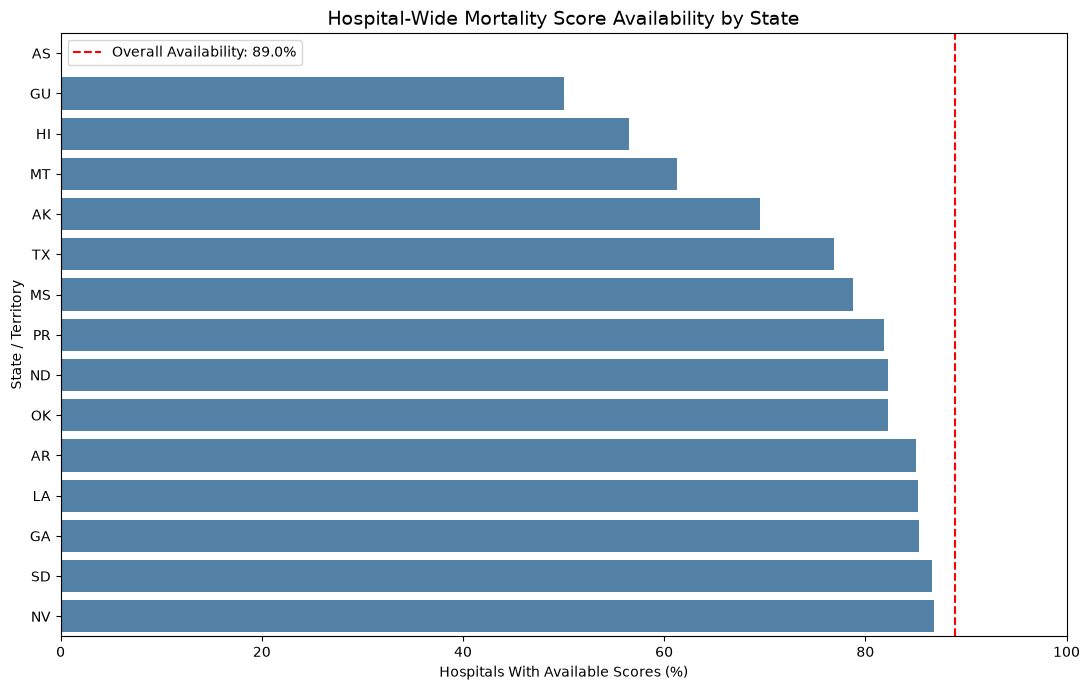

In [54]:
# Select the 15 states and territories with the lowest score availability
lowest_availability = state_availability.sort_values(
    "Availability_Percent",
    ascending=True
).head(15)

# Create a horizontal bar chart of score availability
plt.figure(figsize=(11, 7))

sns.barplot(
    data=lowest_availability.reset_index(),
    x="Availability_Percent",
    y="State",
    color="steelblue"
)

# Add chart title and axis labels
plt.title(
    "Hospital-Wide Mortality Score Availability by State",
    fontsize=14
)
plt.xlabel("Hospitals With Available Scores (%)")
plt.ylabel("State / Territory")

# Set the percentage axis from 0 to 100
plt.xlim(0, 100)

# Add a vertical reference line for overall score availability
overall_availability = (
    mortality_df["Score_Numeric"].notna().mean() * 100
)

plt.axvline(
    overall_availability,
    color="red",
    linestyle="--",
    label=f"Overall Availability: {overall_availability:.1f}%"
)

# Display the legend and improve chart layout
plt.legend()
plt.tight_layout()
plt.show()

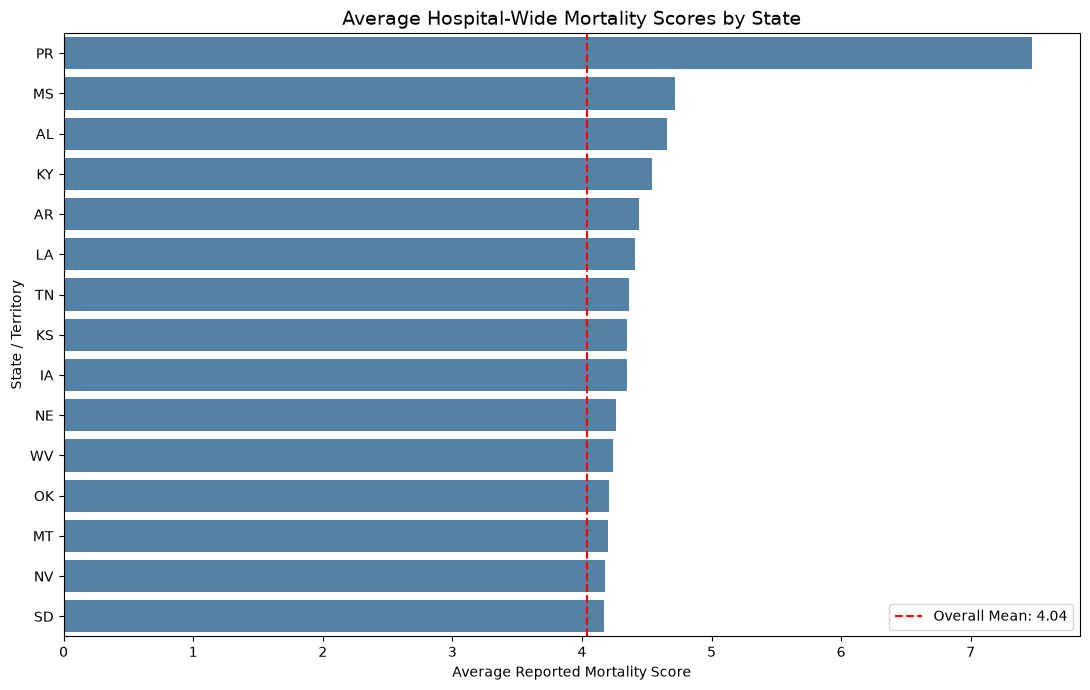

In [55]:
# Select states and territories with at least 30 valid hospital scores
state_comparison = state_summary[
    state_summary["Hospital_Count"] >= 30
].copy()

# Identify the 15 locations with the highest average reported scores
top_states = (
    state_comparison
    .sort_values("Average_Score", ascending=False)
    .head(15)
    .reset_index()
)

# Create a horizontal bar chart comparing average mortality scores
plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_states,
    x="Average_Score",
    y="State",
    color="steelblue"
)

# Add a reference line showing the overall mean across valid hospital records
overall_mean = mortality_valid["Score_Numeric"].mean()

plt.axvline(
    overall_mean,
    color="red",
    linestyle="--",
    label=f"Overall Mean: {overall_mean:.2f}"
)

# Add chart title and descriptive axis labels
plt.title(
    "Average Hospital-Wide Mortality Scores by State",
    fontsize=14
)
plt.xlabel("Average Reported Mortality Score")
plt.ylabel("State / Territory")

# Display the legend and improve chart spacing
plt.legend()
plt.tight_layout()
plt.show()

In [56]:
# Create a copy of valid hospital-wide mortality records
comparison_df = mortality_valid.copy()

# Categorize hospitals into Puerto Rico and all other locations
comparison_df["Location_Group"] = np.where(
    comparison_df["State"] == "PR",
    "Puerto Rico",
    "Other States and Territories"
)

# Calculate descriptive statistics for each location group
group_statistics = comparison_df.groupby("Location_Group")[
    "Score_Numeric"
].agg(["count", "mean", "median", "std", "min", "max"])

# Display the summary statistics rounded to two decimal places
group_statistics.round(2)

,count,mean,median,std,min,max
Location_Group,,,,,,
Other States and Territories,4216,4.00,3.9,0.74,1.6,8.4
Puerto Rico,45,7.47,7.6,2.09,3.4,12.8


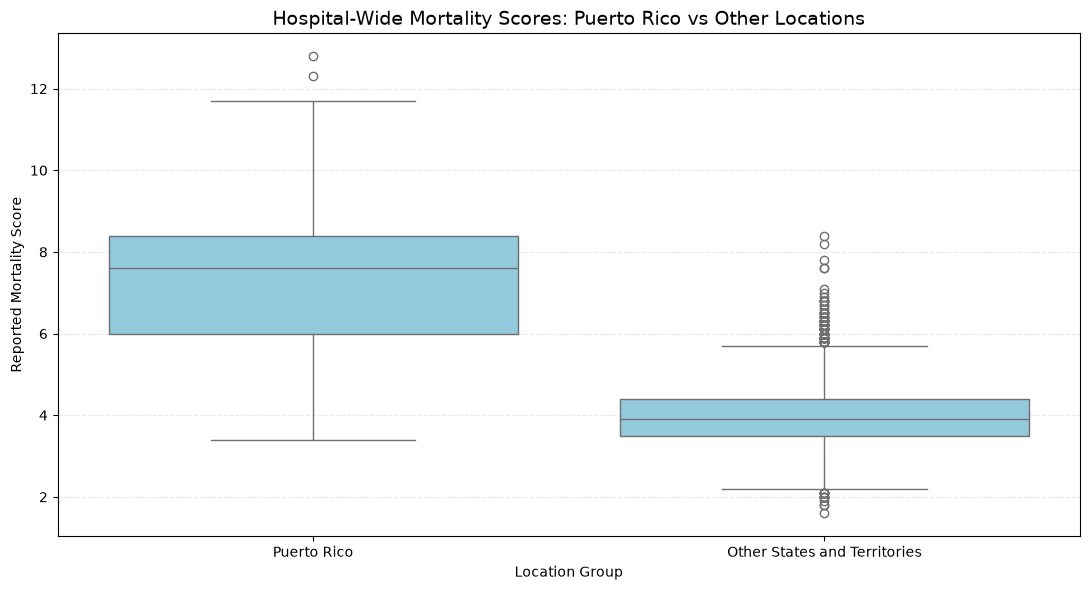

In [57]:
# Create a side-by-side box plot comparing reported mortality scores
plt.figure(figsize=(11, 6))

# Compare the distribution of scores between the two location groups
sns.boxplot(
    data=comparison_df,
    x="Location_Group",
    y="Score_Numeric",
    order=["Puerto Rico", "Other States and Territories"],
    color="skyblue"
)

# Add a descriptive title and axis labels
plt.title(
    "Hospital-Wide Mortality Scores: Puerto Rico vs Other Locations",
    fontsize=14
)
plt.xlabel("Location Group")
plt.ylabel("Reported Mortality Score")

# Add horizontal gridlines to make score differences easier to read
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Improve spacing and display the chart
plt.tight_layout()
plt.show()

In [58]:
# Import the Mann-Whitney U test from SciPy
from scipy.stats import mannwhitneyu

# Extract numeric mortality scores for Puerto Rico hospitals
pr_scores = comparison_df.loc[
    comparison_df["Location_Group"] == "Puerto Rico",
    "Score_Numeric"
]

# Extract numeric mortality scores for all other locations
other_scores = comparison_df.loc[
    comparison_df["Location_Group"] == "Other States and Territories",
    "Score_Numeric"
]

# Perform a two-sided Mann-Whitney U test
u_statistic, p_value = mannwhitneyu(
    pr_scores,
    other_scores,
    alternative="two-sided"
)

# Display the test statistic and p-value
print("Mann-Whitney U Statistic:", round(u_statistic, 2))
print("P-value:", f"{p_value:.6g}")

# Interpret the result using a 5% significance threshold
if p_value < 0.05:
    print("Result: Statistically significant difference detected.")
else:
    print("Result: No statistically significant difference detected.")

Mann-Whitney U Statistic: 181920.0
P-value: 2.48578e-26
Result: Statistically significant difference detected.


In [59]:
# Calculate the sample size for each comparison group
n_pr = len(pr_scores)
n_other = len(other_scores)

# Calculate the common-language effect size:
# Probability that a randomly selected Puerto Rico score exceeds
# a randomly selected score from other locations, counting ties as half
probability_superiority = u_statistic / (n_pr * n_other)

# Convert the probability into rank-biserial correlation
rank_biserial = 2 * probability_superiority - 1

# Calculate the observed difference between group medians
median_difference = pr_scores.median() - other_scores.median()

# Display the effect-size results
print("Puerto Rico sample size:", n_pr)
print("Other locations sample size:", n_other)
print("Probability of superiority:", round(probability_superiority, 4))
print("Rank-biserial correlation:", round(rank_biserial, 4))
print("Difference in medians:", round(median_difference, 2))

Puerto Rico sample size: 45
Other locations sample size: 4216
Probability of superiority: 0.9589
Rank-biserial correlation: 0.9178
Difference in medians: 3.7


In [60]:
# Examine reporting periods for each location group
# This helps determine whether scores cover comparable time windows

reporting_periods = comparison_df.groupby(
    ["Location_Group", "Start Date", "End Date"]
).agg(
    Hospital_Count=("Facility ID", "nunique")
).reset_index()

# Display the reporting periods and number of hospitals in each group
reporting_periods.sort_values(
    ["Location_Group", "Hospital_Count"],
    ascending=[True, False]
)

,Location_Group,Start Date,End Date,Hospital_Count
0,Other States and Territories,07/01/2024,06/30/2025,4216
1,Puerto Rico,07/01/2024,06/30/2025,45


In [61]:
# Examine national comparison categories for hospital-wide mortality
# This helps determine whether national benchmark information is available

# Count each national comparison category
national_comparison_counts = mortality_df[
    "Compared to National"
].value_counts(dropna=False)

# Display the category counts
print("National comparison categories:")
print(national_comparison_counts)

# Compare national comparison categories between Puerto Rico and other locations
mortality_df["Location_Group"] = np.where(
    mortality_df["State"] == "PR",
    "Puerto Rico",
    "Other States and Territories"
)

# Create a cross-tabulation of location and national comparison status
pd.crosstab(
    mortality_df["Location_Group"],
    mortality_df["Compared to National"]
)

National comparison categories:
Compared to National
Not Available    4790
Name: count, dtype: int64


Compared to National,Not Available
Location_Group,
Other States and Territories,4735
Puerto Rico,55


In [62]:
# Inspect the identifier and supporting fields for hospital-wide mortality
# This helps us understand the measure before interpreting its scores

# Display unique measure identifiers
print("Measure IDs:")
print(mortality_df["Measure ID"].unique())

# Examine the most common denominator values
print("\nDenominator values:")
print(mortality_df["Denominator"].value_counts().head(10))

# Examine available explanatory footnotes
print("\nFootnote values:")
print(mortality_df["Footnote"].value_counts(dropna=False).head(10))

Measure IDs:
<StringArray>
['Hybrid_HWM']
Length: 1, dtype: str

Denominator values:
Denominator
Not Available    529
38                22
35                18
43                16
58                16
28                15
56                14
44                14
55                13
69                13
Name: count, dtype: int64

Footnote values:
Footnote
NaN    4192
1       212
19      172
5       141
29       68
7         4
23        1
Name: count, dtype: int64


In [63]:
# Investigate whether unavailable mortality scores are associated with footnotes

# Create a descriptive category for numeric score availability
mortality_df["Score_Status"] = np.where(
    mortality_df["Score_Numeric"].notna(),
    "Available",
    "Not Available"
)

# Replace blank footnotes with a label for easier analysis
mortality_df["Footnote_Category"] = (
    mortality_df["Footnote"]
    .fillna("No Footnote")
    .astype(str)
)

# Count available and unavailable scores for each footnote category
footnote_summary = pd.crosstab(
    mortality_df["Footnote_Category"],
    mortality_df["Score_Status"]
)

# Display the results
footnote_summary

Score_Status,Available,Not Available
Footnote_Category,,
1,0,212
19,0,172
23,1,0
29,68,0
5,0,141
7,0,4
No Footnote,4192,0


In [64]:
# Create a category identifying whether denominator data is available
mortality_df["Denominator_Status"] = np.where(
    mortality_df["Denominator"] == "Not Available",
    "Not Available",
    "Available"
)

# Compare denominator availability with mortality score availability
denominator_summary = pd.crosstab(
    mortality_df["Denominator_Status"],
    mortality_df["Score_Status"]
)

# Display the relationship between denominator and score availability
denominator_summary

Score_Status,Available,Not Available
Denominator_Status,,
Available,4261,0
Not Available,0,529


In [65]:
# Check whether any hospital appears more than once for this mortality measure
duplicate_count = mortality_df.duplicated(
    subset=["Facility ID"]
).sum()

# Count the total records and unique hospital identifiers
total_records = len(mortality_df)
unique_hospitals = mortality_df["Facility ID"].nunique()

# Display the duplicate-check results
print("Total records:", total_records)
print("Unique hospitals:", unique_hospitals)
print("Duplicate hospital records:", duplicate_count)

Total records: 4790
Unique hospitals: 4790
Duplicate hospital records: 0


In [66]:
# Validate the range and completeness of hospital-wide mortality scores

# Count negative and zero scores
negative_scores = (mortality_valid["Score_Numeric"] < 0).sum()
zero_scores = (mortality_valid["Score_Numeric"] == 0).sum()

# Identify the minimum and maximum reported scores
minimum_score = mortality_valid["Score_Numeric"].min()
maximum_score = mortality_valid["Score_Numeric"].max()

# Calculate the number of unique numeric scores
unique_scores = mortality_valid["Score_Numeric"].nunique()

# Display the validation results
print("Negative scores:", negative_scores)
print("Zero scores:", zero_scores)
print("Minimum score:", minimum_score)
print("Maximum score:", maximum_score)
print("Unique numeric scores:", unique_scores)

Negative scores: 0
Zero scores: 0
Minimum score: 1.6
Maximum score: 12.8
Unique numeric scores: 75


In [67]:
# Create a summary of hospital-wide mortality data quality

# Calculate the number of records with valid numeric scores
available_count = mortality_df["Score_Numeric"].notna().sum()

# Calculate the number of records without valid numeric scores
unavailable_count = mortality_df["Score_Numeric"].isna().sum()

# Build a table summarizing key data-quality metrics
quality_summary = pd.DataFrame({
    "Metric": [
        "Total Hospital Records",
        "Unique Hospitals",
        "Available Scores",
        "Unavailable Scores",
        "Score Availability (%)",
        "Duplicate Hospital Records",
        "Negative Scores",
        "Zero Scores",
        "Minimum Reported Score",
        "Maximum Reported Score"
    ],
    "Value": [
        len(mortality_df),
        mortality_df["Facility ID"].nunique(),
        available_count,
        unavailable_count,
        round(available_count / len(mortality_df) * 100, 2),
        mortality_df.duplicated(subset=["Facility ID"]).sum(),
        (mortality_valid["Score_Numeric"] < 0).sum(),
        (mortality_valid["Score_Numeric"] == 0).sum(),
        mortality_valid["Score_Numeric"].min(),
        mortality_valid["Score_Numeric"].max()
    ]
})

# Display the completed data-quality summary
quality_summary

,Metric,Value
0,Total Hospital Records,4790.00
1,Unique Hospitals,4790.00
2,Available Scores,4261.00
3,Unavailable Scores,529.00
4,Score Availability (%),88.96
5,Duplicate Hospital Records,0.00
6,Negative Scores,0.00
7,Zero Scores,0.00
8,Minimum Reported Score,1.60
9,Maximum Reported Score,12.80


In [68]:
# Import Path to manage project file locations
from pathlib import Path

# Define the reports folder relative to the notebooks directory
reports_folder = Path("../reports")

# Create the reports folder if it does not already exist
reports_folder.mkdir(parents=True, exist_ok=True)

# Save the hospital mortality data-quality summary as a CSV file
quality_summary.to_csv(
    reports_folder / "hospital_mortality_data_quality.csv",
    index=False
)

# Confirm that the report was saved successfully
print("Data-quality report saved successfully!")

Data-quality report saved successfully!


In [69]:
# Create a summary of the Puerto Rico vs other locations analysis
statistical_summary = pd.DataFrame({
    "Metric": [
        "Puerto Rico Hospital Count",
        "Other Locations Hospital Count",
        "Puerto Rico Mean Score",
        "Other Locations Mean Score",
        "Puerto Rico Median Score",
        "Other Locations Median Score",
        "Median Difference",
        "Mann-Whitney U Statistic",
        "P-Value",
        "Probability of Superiority",
        "Rank-Biserial Correlation"
    ],
    "Value": [
        len(pr_scores),
        len(other_scores),
        pr_scores.mean(),
        other_scores.mean(),
        pr_scores.median(),
        other_scores.median(),
        median_difference,
        u_statistic,
        p_value,
        probability_superiority,
        rank_biserial
    ]
})

# Save the statistical summary to the reports folder
statistical_summary.to_csv(
    reports_folder / "hospital_mortality_statistical_summary.csv",
    index=False
)

# Display the statistical summary
statistical_summary

,Metric,Value
0,Puerto Rico Hospital Count,4.500000e+01
1,Other Locations Hospital Count,4.216000e+03
2,Puerto Rico Mean Score,7.471111e+00
3,Other Locations Mean Score,3.999454e+00
4,Puerto Rico Median Score,7.600000e+00
5,Other Locations Median Score,3.900000e+00
6,Median Difference,3.700000e+00
7,Mann-Whitney U Statistic,1.819200e+05
8,P-Value,2.485781e-26
9,Probability of Superiority,9.588868e-01


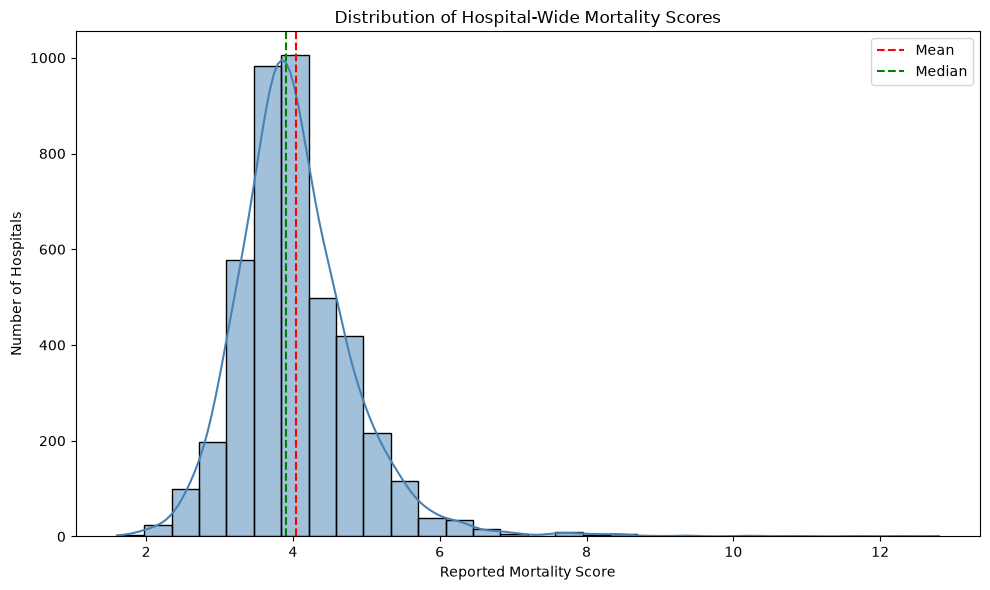

Mortality distribution chart saved successfully!


In [70]:
# Define the dashboards folder for storing portfolio visualizations
dashboards_folder = Path("../dashboards")

# Create the folder if it does not already exist
dashboards_folder.mkdir(parents=True, exist_ok=True)

# Create a histogram of valid hospital-wide mortality scores
plt.figure(figsize=(10, 6))

sns.histplot(
    data=mortality_valid,
    x="Score_Numeric",
    bins=30,
    kde=True,
    color="steelblue"
)

# Add reference lines for the mean and median
plt.axvline(
    mortality_valid["Score_Numeric"].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

plt.axvline(
    mortality_valid["Score_Numeric"].median(),
    color="green",
    linestyle="--",
    label="Median"
)

# Add descriptive labels and a legend
plt.title("Distribution of Hospital-Wide Mortality Scores")
plt.xlabel("Reported Mortality Score")
plt.ylabel("Number of Hospitals")
plt.legend()

# Adjust spacing before saving the chart
plt.tight_layout()

# Save the visualization as a high-resolution PNG image
plt.savefig(
    dashboards_folder / "mortality_score_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the chart and confirm the file was saved
plt.show()
print("Mortality distribution chart saved successfully!")

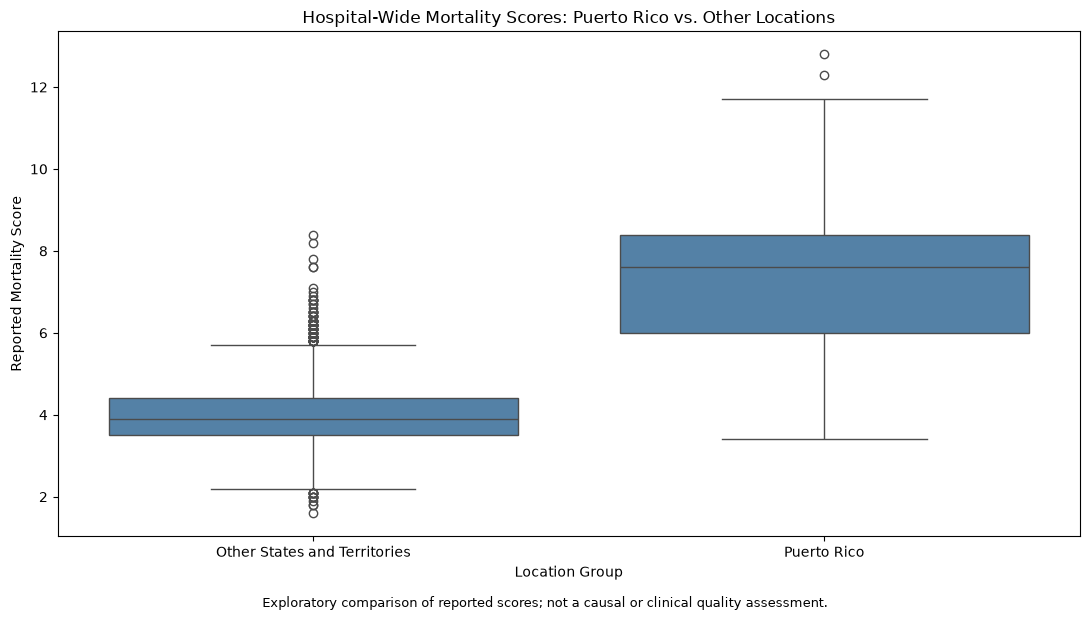

Puerto Rico comparison chart saved successfully!


In [71]:
# Create a boxplot comparing mortality scores between Puerto Rico and other locations
plt.figure(figsize=(11, 6))

# Display the distribution of scores for each location group
sns.boxplot(
    data=comparison_df,
    x="Location_Group",
    y="Score_Numeric",
    color="steelblue"
)

# Add a descriptive title and axis labels
plt.title("Hospital-Wide Mortality Scores: Puerto Rico vs. Other Locations")
plt.xlabel("Location Group")
plt.ylabel("Reported Mortality Score")

# Add a note about the exploratory nature of the comparison
plt.figtext(
    0.5, -0.02,
    "Exploratory comparison of reported scores; not a causal or clinical quality assessment.",
    ha="center",
    fontsize=9
)

# Adjust spacing to prevent labels from being cut off
plt.tight_layout()

# Save the chart as a high-resolution PNG file
plt.savefig(
    dashboards_folder / "puerto_rico_vs_other_locations_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the chart
plt.show()

# Confirm that the visualization was saved
print("Puerto Rico comparison chart saved successfully!")

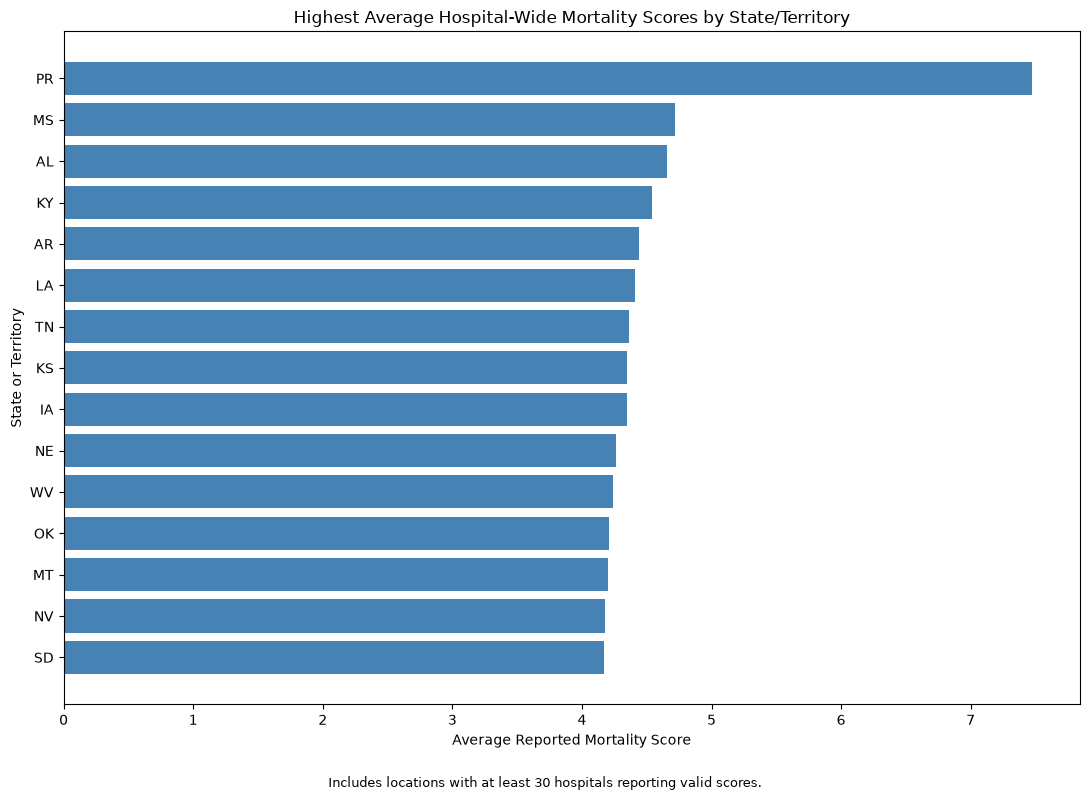

State mortality comparison chart saved successfully!


In [72]:
# Select states and territories with at least 30 valid hospital scores
eligible_states = state_summary[
    state_summary["Hospital_Count"] >= 30
].copy()

# Select the 15 locations with the highest average reported scores
top_15_states = eligible_states.nlargest(
    15, "Average_Score"
).sort_values("Average_Score")

# Create a horizontal bar chart
plt.figure(figsize=(11, 8))

# Plot the average reported score for each selected location
plt.barh(
    top_15_states.index,
    top_15_states["Average_Score"],
    color="steelblue"
)

# Add descriptive chart labels
plt.title("Highest Average Hospital-Wide Mortality Scores by State/Territory")
plt.xlabel("Average Reported Mortality Score")
plt.ylabel("State or Territory")

# Explain the sample-size restriction
plt.figtext(
    0.5, 0.01,
    "Includes locations with at least 30 hospitals reporting valid scores.",
    ha="center",
    fontsize=9
)

# Adjust spacing to keep labels visible
plt.tight_layout(rect=[0, 0.04, 1, 1])

# Save the chart to the dashboards folder
plt.savefig(
    dashboards_folder / "state_mortality_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the chart
plt.show()

# Confirm that the file was saved
print("State mortality comparison chart saved successfully!")

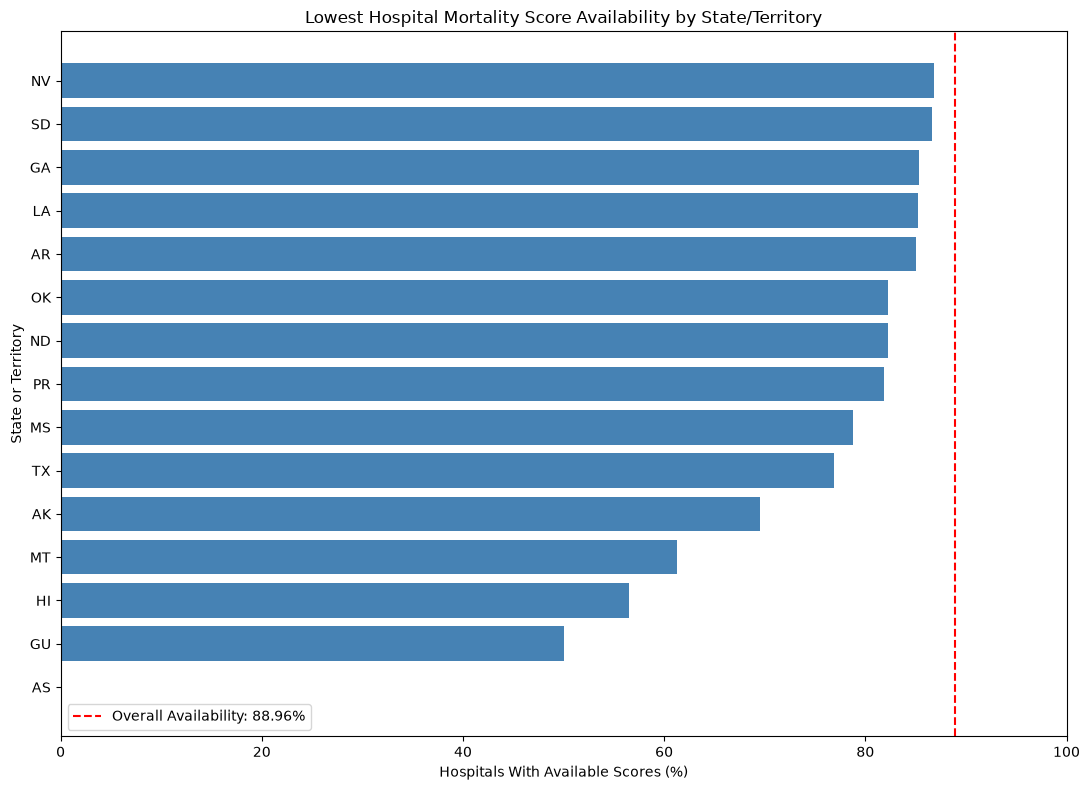

State score availability chart saved successfully!


In [76]:
# Calculate the percentage of hospitals with available mortality scores
state_availability["Availability_Percentage"] = (
    state_availability["Available_Scores"]
    / state_availability["Total_Hospitals"]
    * 100
).round(2)

# Select the 15 states or territories with the lowest score availability
lowest_availability = state_availability.nsmallest(
    15, "Availability_Percentage"
).sort_values("Availability_Percentage")

# Create a horizontal bar chart
plt.figure(figsize=(11, 8))

# Plot the percentage of hospitals with available scores
plt.barh(
    lowest_availability.index,
    lowest_availability["Availability_Percentage"],
    color="steelblue"
)

# Calculate overall hospital score availability
overall_availability = (
    mortality_df["Score_Numeric"].notna().mean() * 100
)

# Add a reference line showing overall availability
plt.axvline(
    overall_availability,
    color="red",
    linestyle="--",
    label=f"Overall Availability: {overall_availability:.2f}%"
)

# Add chart title and axis labels
plt.title("Lowest Hospital Mortality Score Availability by State/Territory")
plt.xlabel("Hospitals With Available Scores (%)")
plt.ylabel("State or Territory")
plt.xlim(0, 100)
plt.legend()

# Adjust chart spacing
plt.tight_layout()

# Save the chart as a high-resolution PNG file
plt.savefig(
    dashboards_folder / "state_score_availability.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the chart
plt.show()

# Confirm that the chart was saved
print("State score availability chart saved successfully!")

In [77]:
# Create a structured summary of the project's main analytical findings
final_findings = pd.DataFrame({
    "Finding": [
        "Total Hospitals Analyzed",
        "Hospitals With Available Scores",
        "Overall Score Availability (%)",
        "Overall Mean Mortality Score",
        "Overall Median Mortality Score",
        "Puerto Rico Mean Score",
        "Other Locations Mean Score",
        "Median Score Difference",
        "Mann-Whitney U P-Value",
        "Probability of Superiority (%)"
    ],
    "Value": [
        mortality_df["Facility ID"].nunique(),
        mortality_valid["Facility ID"].nunique(),
        round(mortality_df["Score_Numeric"].notna().mean() * 100, 2),
        round(mortality_valid["Score_Numeric"].mean(), 2),
        round(mortality_valid["Score_Numeric"].median(), 2),
        round(pr_scores.mean(), 2),
        round(other_scores.mean(), 2),
        round(pr_scores.median() - other_scores.median(), 2),
        p_value,
        round(probability_superiority * 100, 2)
    ]
})

# Save the findings to a CSV file in the reports folder
final_findings.to_csv(
    reports_folder / "hospital_mortality_final_findings.csv",
    index=False
)

# Display the final findings table
display(final_findings)

# Confirm that the report was saved
print("Final statistical findings report saved successfully!")

,Finding,Value
0,Total Hospitals Analyzed,4.790000e+03
1,Hospitals With Available Scores,4.261000e+03
2,Overall Score Availability (%),8.896000e+01
3,Overall Mean Mortality Score,4.040000e+00
4,Overall Median Mortality Score,3.900000e+00
5,Puerto Rico Mean Score,7.470000e+00
6,Other Locations Mean Score,4.000000e+00
7,Median Score Difference,3.700000e+00
8,Mann-Whitney U P-Value,2.485781e-26
9,Probability of Superiority (%),9.589000e+01


Final statistical findings report saved successfully!


### Measure Definition and Interpretation

**Measure:** Hybrid Hospital-Wide All-Cause Risk Standardized Mortality Rate (Hybrid_HWM)

**Reporting period:** July 1, 2024 – June 30, 2025

**Definition:** A hospital-level, risk-standardized rate measuring deaths from any cause within 30 days of hospital admission among eligible patients.

**Score interpretation:** Lower reported mortality rates indicate better performance on this specific measure.

**Key limitations:**
- Results are observational and do not establish causation.
- Missing hospital scores may affect geographic comparisons.
- Puerto Rico and other locations have substantially different sample sizes.
- The Puerto Rico comparison was selected after exploring the data, so its p-value should be treated as exploratory rather than confirmatory.
- This single measure does not capture overall hospital quality.

**Sources:**
- CMS Hybrid Measures: https://qualitynet.cms.gov/inpatient/measures/hybrid
- CMS Measure Methodology: https://www.cms.gov/medicare/quality/initiatives/hospital-quality-initiative/measure-methodology

In [78]:

# Import pyodbc to inspect available SQL Server connection drivers
import pyodbc

# Display the ODBC drivers installed on this Windows computer
print("Available ODBC Drivers:")
for driver in pyodbc.drivers():
    print(driver)


Available ODBC Drivers:
SQL Server
Tally ODBC Driver64
ODBC Driver 17 for SQL Server
ODBC Driver 18 for SQL Server
SQL Server Native Client 11.0
Microsoft Access Driver (*.mdb, *.accdb)
Microsoft Excel Driver (*.xls, *.xlsx, *.xlsm, *.xlsb)
Microsoft Access Text Driver (*.txt, *.csv)
Microsoft Access dBASE Driver (*.dbf, *.ndx, *.mdx)


In [79]:

# Import libraries for connecting Python to SQL Server
import pyodbc
import pandas as pd

# Configure the connection using Windows Authentication
connection_string = (
    "DRIVER={ODBC Driver 18 for SQL Server};"
    "SERVER=Sindhu;"
    "DATABASE=HospitalQualityAnalytics;"
    "Trusted_Connection=yes;"
    "Encrypt=yes;"
    "TrustServerCertificate=yes;"
)

# Connect to SQL Server and test access to the database
try:
    with pyodbc.connect(connection_string, timeout=10) as connection:
        print("Successfully connected to SQL Server!")

        # Retrieve a small sample from our cleaned mortality view
        query = """
        SELECT TOP (5)
            Facility_ID,
            Facility_Name,
            State,
            Mortality_Rate
        FROM dbo.vw_HospitalMortalityAnalysis;
        """

        sample_df = pd.read_sql_query(query, connection)
        display(sample_df)

except pyodbc.Error as error:
    print("SQL Server connection failed:")
    print(error)


Successfully connected to SQL Server!


C:\Users\naini\AppData\Local\Temp\ipykernel_21188\2989645138.py:30: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  sample_df = pd.read_sql_query(query, connection)


,Facility_ID,Facility_Name,State,Mortality_Rate
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,AL,4.4
1,010005,MARSHALL MEDICAL CENTERS,AL,5.7
2,010006,NORTH ALABAMA MEDICAL CENTER,AL,5.1
3,010007,MIZELL MEMORIAL HOSPITAL,AL,6.7
4,010011,ST. VINCENT'S EAST,AL,4.3


In [80]:

# Import libraries for SQL Server connectivity and data analysis
import pandas as pd
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

# Configure a SQLAlchemy connection using Windows Authentication
connection_url = URL.create(
    "mssql+pyodbc",
    host="Sindhu",
    database="HospitalQualityAnalytics",
    query={
        "driver": "ODBC Driver 18 for SQL Server",
        "Trusted_Connection": "yes",
        "Encrypt": "yes",
        "TrustServerCertificate": "yes"
    }
)

# Create a reusable database engine
engine = create_engine(connection_url)

# Retrieve the complete validated hospital mortality dataset
query = """
SELECT *
FROM dbo.vw_HospitalMortalityAnalysis;
"""

# Load the SQL view into a pandas DataFrame
with engine.connect() as connection:
    mortality_df = pd.read_sql_query(query, connection)

# Verify the dataset size and preview the records
print("Dataset Shape:", mortality_df.shape)
print("Unique Hospitals:", mortality_df["Facility_ID"].nunique())
print("Available Mortality Scores:", mortality_df["Mortality_Rate"].notna().sum())

display(mortality_df.head())


Dataset Shape: (4790, 15)
Unique Hospitals: 4790
Available Mortality Scores: 4261


,Facility_ID,Facility_Name,State,City_Town,ZIP_Code,Measure_ID,Measure_Name,Mortality_Rate,Score_Status,Denominator_Numeric,Lower_Estimate_Numeric,Higher_Estimate_Numeric,Footnote,Start_Date,End_Date
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,AL,DOTHAN,36301,Hybrid_HWM,Hybrid Hospital-Wide All-Cause Risk Standardiz...,4.4,Available,4972.0,None,None,NaN,2024-07-01,2025-06-30
1,010005,MARSHALL MEDICAL CENTERS,AL,BOAZ,35957,Hybrid_HWM,Hybrid Hospital-Wide All-Cause Risk Standardiz...,5.7,Available,1448.0,None,None,NaN,2024-07-01,2025-06-30
2,010006,NORTH ALABAMA MEDICAL CENTER,AL,FLORENCE,35630,Hybrid_HWM,Hybrid Hospital-Wide All-Cause Risk Standardiz...,5.1,Available,3560.0,None,None,NaN,2024-07-01,2025-06-30
3,010007,MIZELL MEMORIAL HOSPITAL,AL,OPP,36467,Hybrid_HWM,Hybrid Hospital-Wide All-Cause Risk Standardiz...,6.7,Available,267.0,None,None,NaN,2024-07-01,2025-06-30
4,010011,ST. VINCENT'S EAST,AL,BIRMINGHAM,35235,Hybrid_HWM,Hybrid Hospital-Wide All-Cause Risk Standardiz...,4.3,Available,2676.0,None,None,29,2024-07-01,2025-06-30


In [83]:

# Check the structure and data types of the SQL Server dataset
print("Dataset Shape:", mortality_df.shape)

# Verify hospital coverage and mortality score availability
print("Unique Hospitals:", mortality_df["Facility_ID"].nunique())
print("Available Mortality Scores:", mortality_df["Mortality_Rate"].notna().sum())
print("Missing Mortality Scores:", mortality_df["Mortality_Rate"].isna().sum())

# Inspect column data types before statistical analysis
print("\nColumn Data Types:")
print(mortality_df.dtypes)


Dataset Shape: (4790, 15)
Unique Hospitals: 4790
Available Mortality Scores: 4261
Missing Mortality Scores: 529

Column Data Types:
Facility_ID                    str
Facility_Name                  str
State                          str
City_Town                      str
ZIP_Code                       str
Measure_ID                     str
Measure_Name                   str
Mortality_Rate             float64
Score_Status                   str
Denominator_Numeric        float64
Lower_Estimate_Numeric      object
Higher_Estimate_Numeric     object
Footnote                       str
Start_Date                  object
End_Date                    object
dtype: object


In [84]:

# Convert SQL Server mortality scores into a numeric pandas column
# Invalid or missing values will become NaN
mortality_df["Mortality_Rate"] = pd.to_numeric(
    mortality_df["Mortality_Rate"],
    errors="coerce"
)

# Check the data type after conversion
print("Mortality Rate Data Type:", mortality_df["Mortality_Rate"].dtype)

# Confirm the number of usable and missing mortality scores
print("Available Scores:", mortality_df["Mortality_Rate"].notna().sum())
print("Missing Scores:", mortality_df["Mortality_Rate"].isna().sum())


Mortality Rate Data Type: float64
Available Scores: 4261
Missing Scores: 529
